In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## confusion-matrix

**Figure 2: Confusion matrix of the Random Forest classifier predicting Yelp star ratings on the test set.** Each row is normalized over the reviews with that true rating, so the diagonal is per-class recall. Predictions skew toward the extremes: 1- and 5-star reviews are mostly right (0.82 and 0.76), but 2-star reviews go to 1 star as often as to 2 (0.38 vs 0.37) and 4-star reviews to 5 stars as often as to 4 (0.37 vs 0.39).

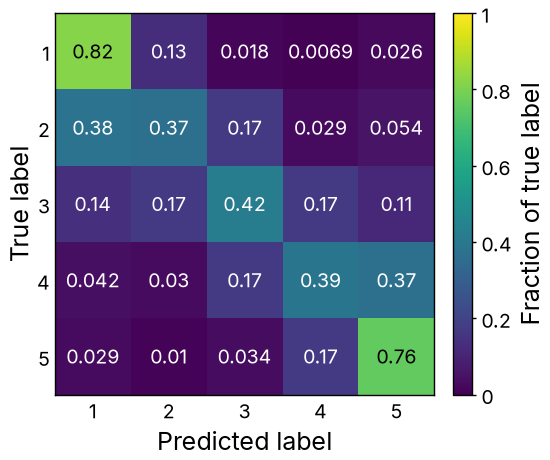

In [2]:
with open("../data/confusion-matrix.json") as f:
    data = json.load(f)
matrix, labels = data["matrix"], data["labels"]

fig, ax = plt.subplots(figsize=(2.75, 2.5), layout="constrained")
im = ax.imshow(matrix, aspect="auto", vmin=0, vmax=1)
for i, row in enumerate(matrix):
    for j, v in enumerate(row):
        ax.text(j, i, f"{v:g}", ha="center", va="center", color=text_color(im.cmap(im.norm(v))))
ax.set_xticks(range(len(labels)), labels=labels)
ax.set_yticks(range(len(labels)), labels=labels)
ax.tick_params(length=0)
ax.grid(False)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
cbar = fig.colorbar(im, ax=ax, label="Fraction of true label")
cbar.ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/confusion-matrix.pdf")
fig.savefig("../outputs/confusion-matrix.png")
plt.show()